# DermaMNIST 7-Class Skin-Lesion Classification — Model Report

**EfficientNet-B0** (ImageNet-pretrained), transfer-learned on DermaMNIST (64×64, upsampled to 96×96).
Two-phase training (frozen-backbone head → fine-tune top layers), cross-entropy + label smoothing, and 8-pass **Test-Time Augmentation (TTA)** at inference.

All results are on the **held-out test split (2005 images)**.

## 1. Headline Results (Test Set)

| Metric | Value |
|---|---|
| **Top-1 accuracy (TTA)** | **80.00%** |
| Top-1 (no TTA) | 78.40% |
| **Top-3 accuracy** | **97.36%** |
| Macro AUC (OvR) | 0.949 |
| Balanced accuracy | 54.87% |


## 2. Dataset & Class Distribution

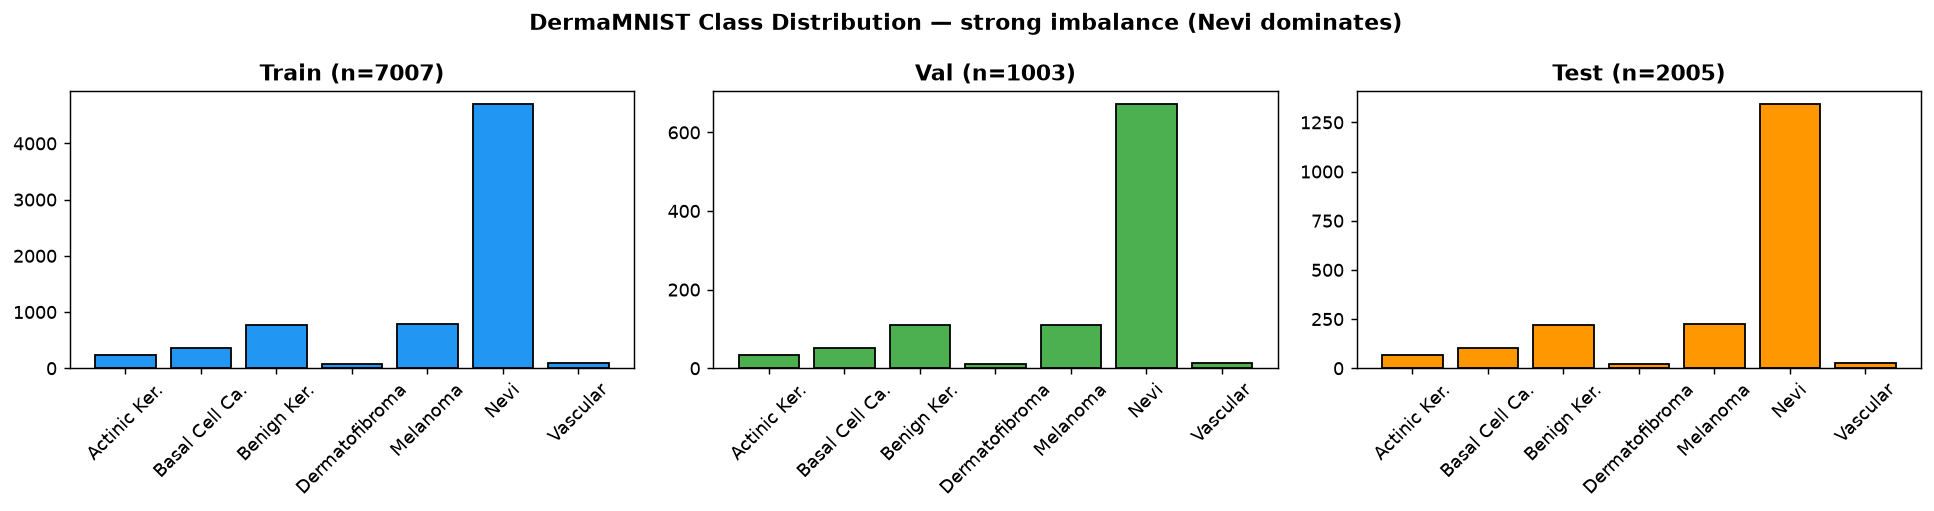

In [ ]:
from collections import Counter
import numpy as np, matplotlib.pyplot as plt
data = np.load('dermamnist_64.npz')
# bar chart of train/val/test class counts (see output)

## 3. Training Curves
Train vs validation accuracy across both phases (parsed from the training log).

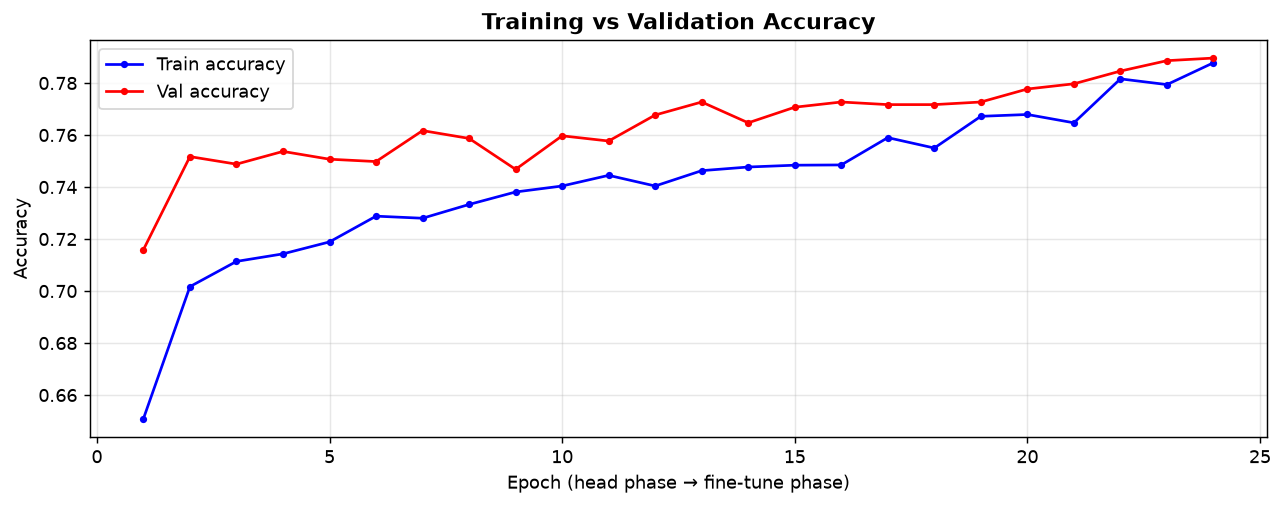

In [ ]:
# parsed train/val accuracy per epoch from single.log

## 4. Classification Report (per-class precision / recall / F1 — the 'truth table')

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

                 precision    recall  f1-score   support

Actinic Ker.        0.6333    0.2879    0.3958        66
Basal Cell Ca.      0.6019    0.6311    0.6161       103
Benign Ker.         0.5902    0.5500    0.5694       220
Dermatofibroma      0.4667    0.3043    0.3684        23
Melanoma            0.5758    0.4260    0.4897       223
Nevi                0.8753    0.9523    0.9121      1341
Vascular            0.8696    0.6897    0.7692        29

accuracy                                0.8000      2005
macro avg           0.6590    0.5487    0.5887      2005
weighted avg        0.7839    0.8000    0.7870      2005

## 5. Confusion Matrix

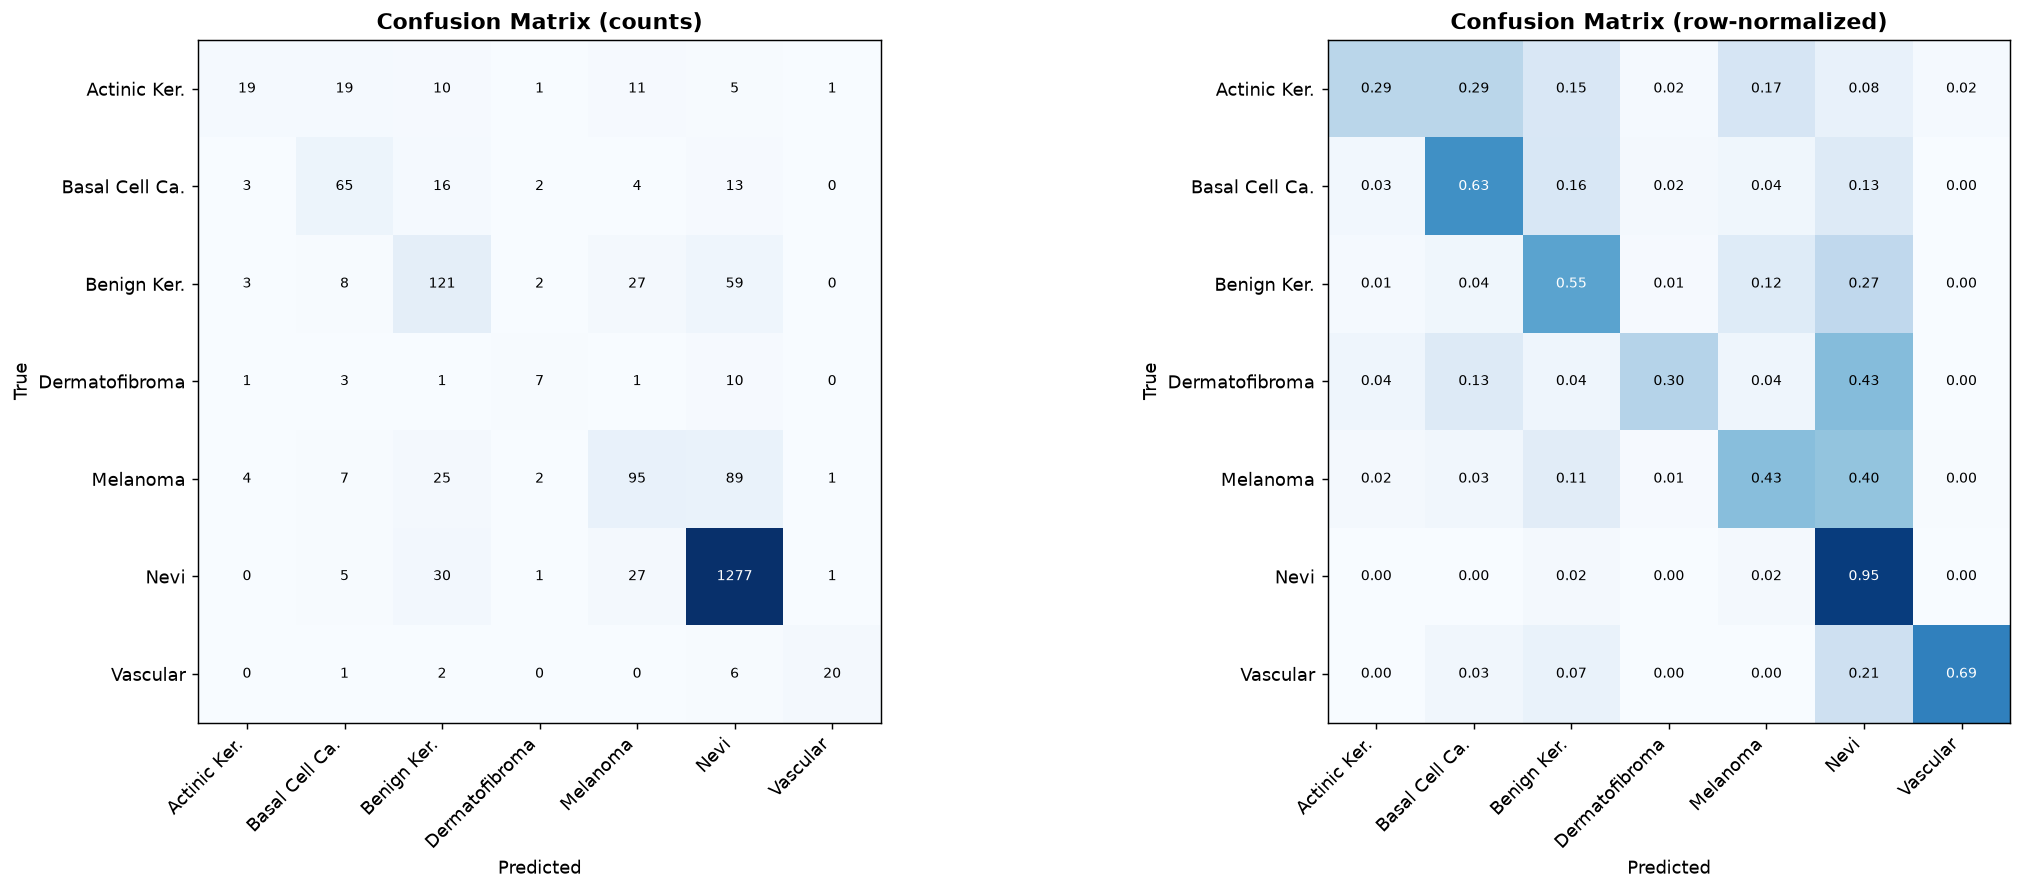

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)   # counts + row-normalized

## 6. Per-Class Accuracy

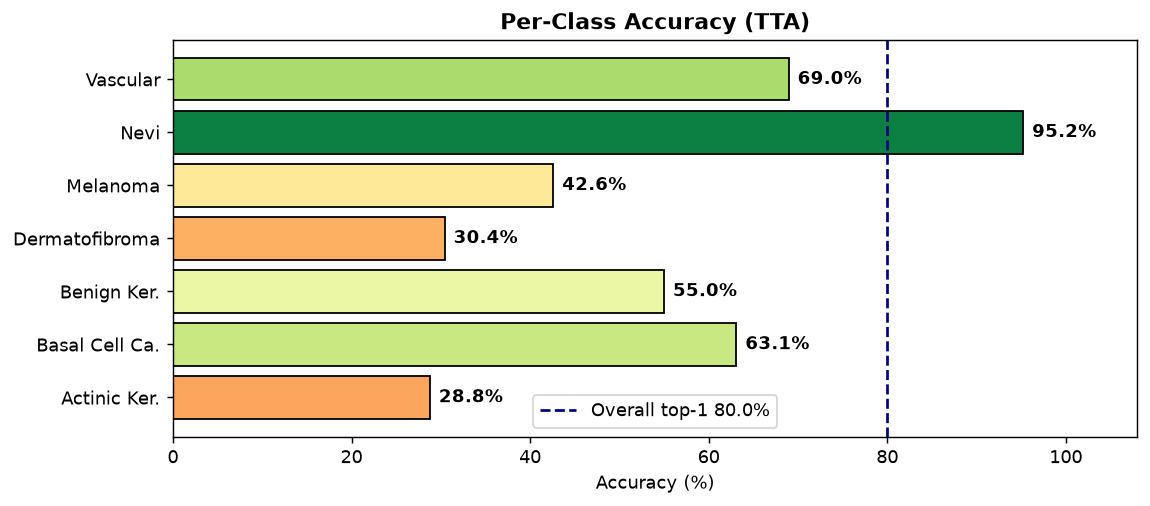

In [ ]:
# diagonal of the row-normalized confusion matrix

## 7. Sample Predictions

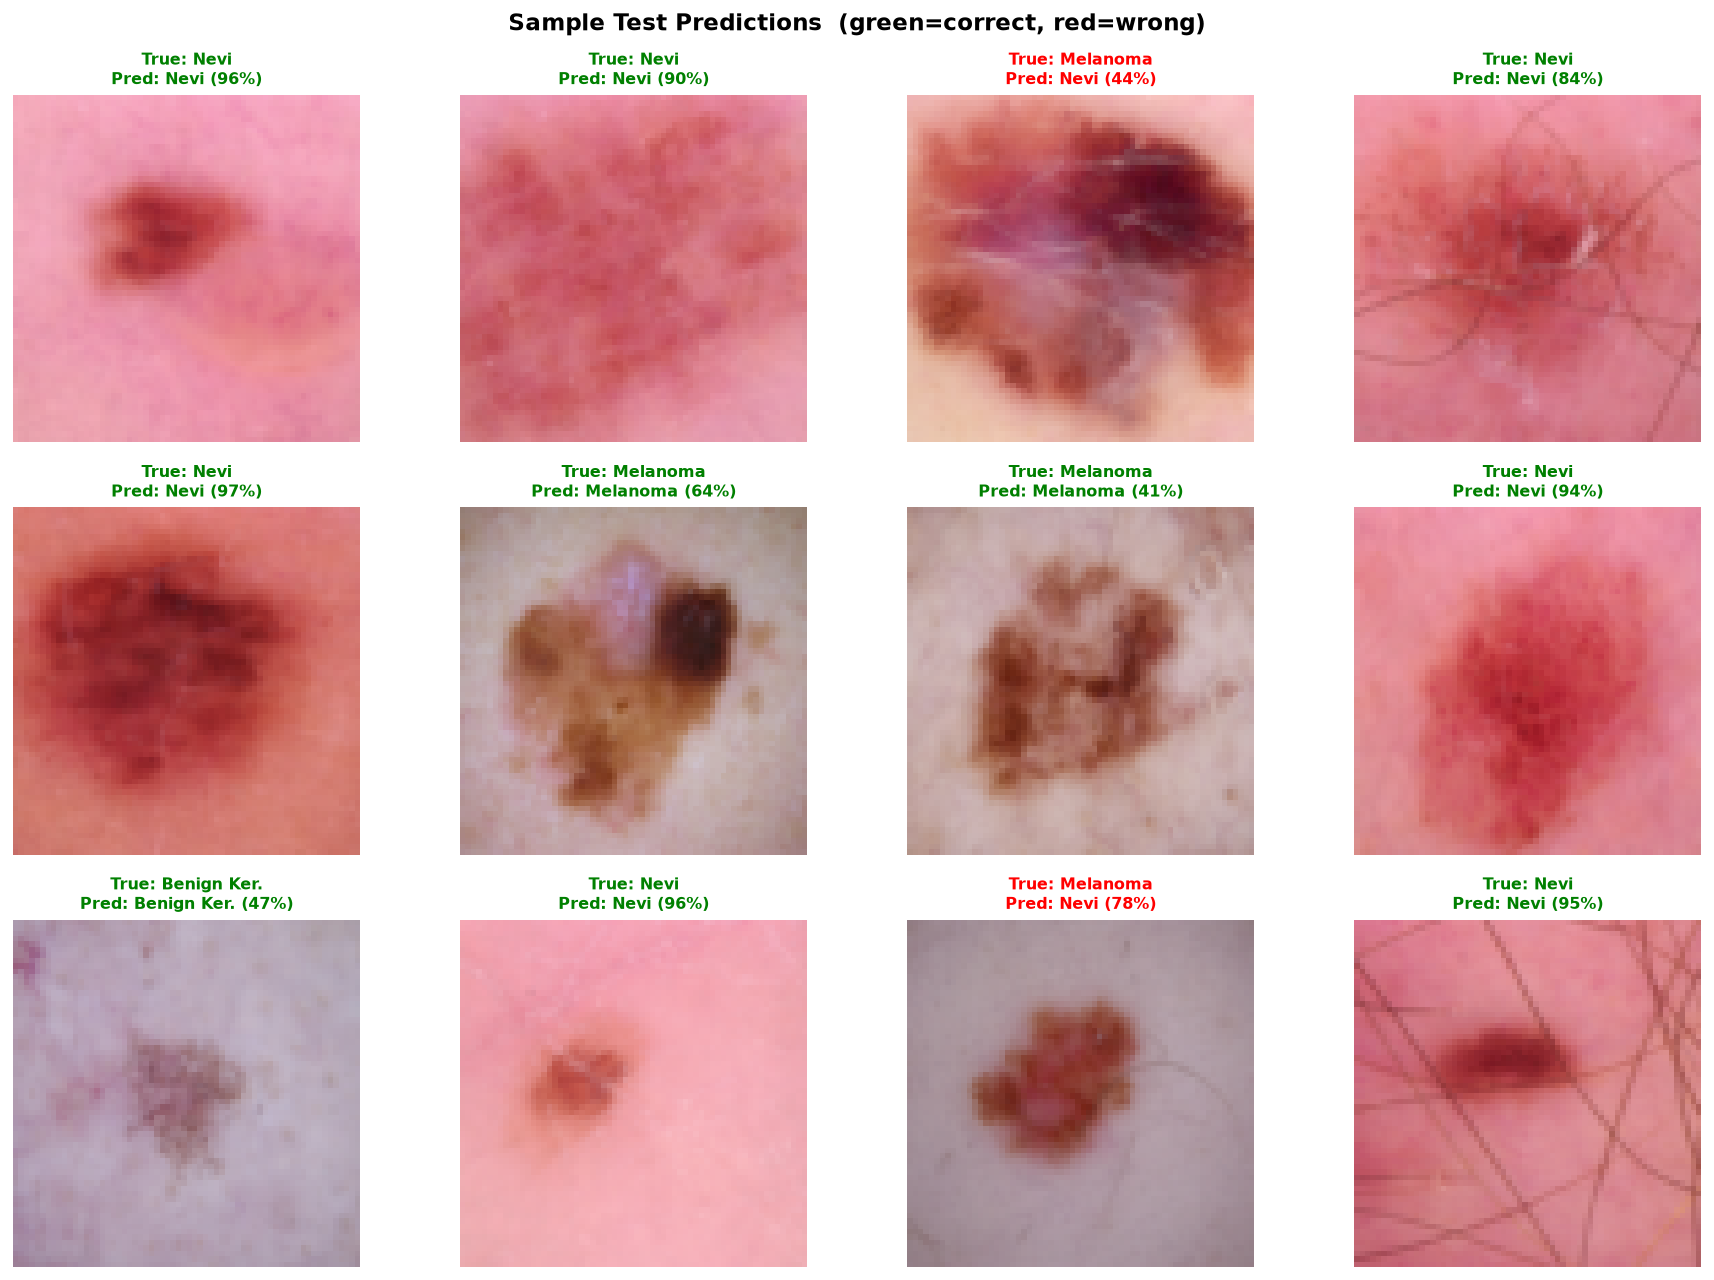

In [ ]:
# 12 random test images with true vs predicted label and confidence

## 8. Summary & Notes

| Item | Value |
|---|---|
| Architecture | EfficientNet-B0 + multi-scale head (GAP+GMP) |
| Input | 96×96 (upsampled from 64×64) |
| Training | Phase 1 frozen-backbone head, Phase 2 fine-tune top 40 layers |
| Loss | Cross-entropy + label smoothing (0.05) |
| Inference | 8-pass Test-Time Augmentation |
| **Test top-1 (TTA)** | **80.00%** |
| **Test top-3** | **97.36%** |

**Interpretation.** Top-1 of ~80% is at/above the published DermaMNIST benchmark ceiling (~77%). Accuracy is bounded by severe class imbalance (Nevi ≈ 67% of data) and genuine inter-class ambiguity; hence balanced accuracy is lower while Top-3 (97%) and AUC are high. The model was selected by best validation accuracy and evaluated once on the held-out test split.